In [44]:
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

from math import pi, log

In [45]:
def RGB_norm(r,g,b):
    return (r/255,g/255,b/255)

COLOR_1 = RGB_norm(255,0,0) # Shear = Red
COLOR_2 = RGB_norm(255,255,0) # Microbuckling = Yellow
COLOR_3 = RGB_norm(0,0,255) # Indentation = Blue

In [46]:
###TUVWXYZ = 6477368
TU = 64
VW = 77
X = 3
YZ = 68

## Face Material
face_density = 1600+40*TU #kg/m^3
face_modulus = 1000*(40+VW) #MPa
face_comp_strength = 200 + (100*X)

## Core Material
core_density = 20 + 3*YZ
core_comp_strength = 0.5 + 4.5*((YZ/100)**(3/2))
core_shear_strength = 0.5 + 3.5*((YZ/100)**(3/2))

# ## A4 Values for Testing
# face_modulus = 70000
# face_comp_strength = 800
# core_comp_strength = 4.5
# core_shear_strength = 3.2

## Design Space
L = 2.5 #meters
b = 0.2 #meters

In [47]:
class beam:
    def __init__(self,b,c,t,sigma_f,sigma_c,tau_c,E_f,L):
        self.b = b
        self.c = c
        self.t = t
        self.d = self.t + self.c
        self.sigma_f = sigma_f
        self.sigma_c = sigma_c
        self.tau_c = tau_c
        self.E_f = E_f
        self.L = L

    def build_mass(self,rho_f,rho_c):
        self.rho_f = rho_f
        self.rho_c = rho_c
        self.M = 2*self.b*self.L*self.t*self.rho_f + self.b*self.L*self.c*self.rho_c

def fail_shear(beam):
    b = beam.b
    d = beam.d
    tau_c = beam.tau_c

    return 2*b*d*tau_c

def fail_microbuckle(beam):
    b = beam.b
    d = beam.d
    t = beam.t
    sigma_f = beam.sigma_f
    L = beam.L

    return (4*b*d*t*sigma_f)/L

def fail_indent(beam):
    b = beam.b
    t = beam.t
    d = beam.d
    E_f = beam.E_f
    sigma_c = beam.sigma_c
    L = beam.L

    return b*t*(((pi*pi*d*E_f*sigma_c*sigma_c)/(3*L))**(1/3))

def fail_type(beam):
    shear_fail_force = fail_shear(beam)
    microbuckle_fail_force = fail_microbuckle(beam)
    indent_fail_force = fail_indent(beam)

    failure = sorted([(shear_fail_force,'Shear',1),(microbuckle_fail_force,"Microbuckle",2),(indent_fail_force,"Indentation",3)])

    # print(failure)
    # print(failure[0])

    return failure[0]


    

## Full Failure Map

Text(0.5, 1.0, 'Failure map of design space')

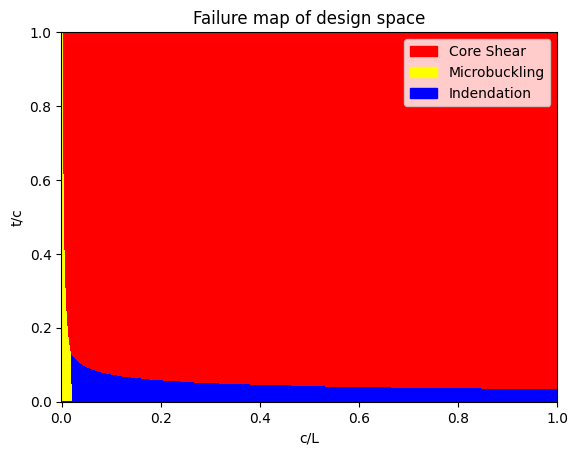

In [48]:
X_res = 1000
Y_res = 1000
X_crop = 1.0
Y_crop = 1.0

x_vals = np.linspace(0,X_crop,X_res,True,dtype='d')
y_vals = np.linspace(0,Y_crop,Y_res,True,dtype='d')

map = np.zeros((X_res,Y_res,3),dtype='d')

for I in range(len(x_vals)):
    i = x_vals[I]
    c = (i*L)
    for J in range(len(y_vals)):
        j = y_vals[J]
        t = (j*c)
        sample = beam(b,c,t,face_comp_strength,core_comp_strength,core_shear_strength,face_modulus,L)
        failure = fail_type(sample)
        mode = failure[2]
        map[J][I] = ((mode==1)*COLOR_1) + ((mode==2)*COLOR_2) + ((mode==3)*COLOR_3)

plt.figure()
X, Y = np.meshgrid(x_vals,y_vals)
plot = plt.pcolormesh(X,Y,map)

legend_handles = [
    mpatches.Patch(color=COLOR_1, label='Core Shear'),
    mpatches.Patch(color=COLOR_2, label='Microbuckling'),
    mpatches.Patch(color=COLOR_3, label='Indendation'),
]

plt.legend(handles=legend_handles)
plt.xlabel('c/L')
plt.ylabel('t/c')
plt.title('Failure map of design space')


## Failue Map Focused on Realistic Region

Text(0.5, 1.0, 'Failure map of design space (zoomed in)')

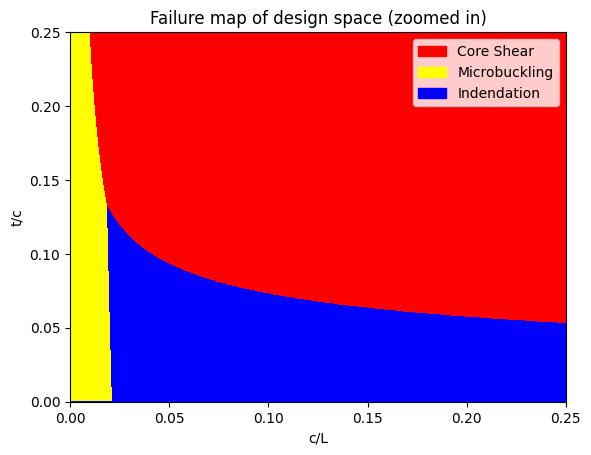

In [49]:
X_res = 1000
Y_res = 1000
X_crop = 0.25
Y_crop = 0.25

x_vals = np.linspace(0,X_crop,X_res,True,dtype='d')
y_vals = np.linspace(0,Y_crop,Y_res,True,dtype='d')

fail_map = np.zeros((X_res,Y_res,3),dtype='d')
mass_map = np.zeros((X_res,Y_res),dtype='d')
force_map = np.zeros((X_res,Y_res),dtype='d')

for I in range(len(x_vals)):
    i = x_vals[I]
    c = (i*L)
    for J in range(len(y_vals)):
        # This part handles the failue mapping
        j = y_vals[J]
        t = (j*c)
        sample = beam(b,c,t,face_comp_strength,core_comp_strength,core_shear_strength,face_modulus,L)
        failure = fail_type(sample)
        mode = failure[2]
        fail_map[J][I] = ((mode==1)*COLOR_1) + ((mode==2)*COLOR_2) + ((mode==3)*COLOR_3)

        # This part handles the unitless Mass contour lines
        sample.build_mass(face_density,core_density)
        mass_map[J][I] = sample.M / (b*L*L*sample.rho_f)

        # This part handles the unitless Force contour lines
        force_map[J][I] = failure[0] / (b*L*sample.sigma_f)


plt.figure()
X, Y = np.meshgrid(x_vals,y_vals)
plot = plt.pcolormesh(X,Y,fail_map)

legend_handles = [
    mpatches.Patch(color=COLOR_1, label='Core Shear'),
    mpatches.Patch(color=COLOR_2, label='Microbuckling'),
    mpatches.Patch(color=COLOR_3, label='Indendation'),
]

plt.legend(handles=legend_handles)
plt.xlabel('c/L')
plt.ylabel('t/c')
plt.title('Failure map of design space (zoomed in)')


Text(0.5, 1.0, 'Contours of constant mass')

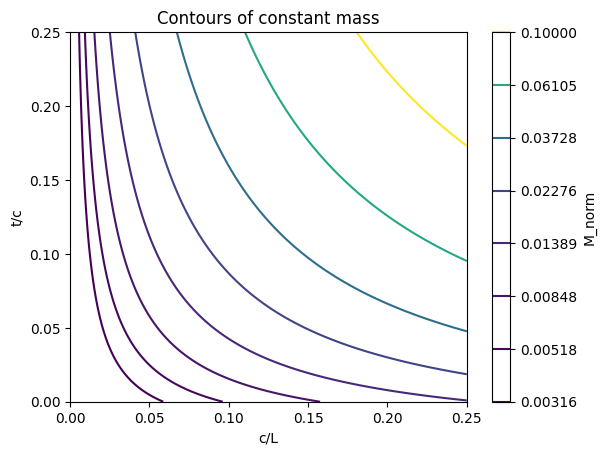

In [50]:
mass_spacing = np.logspace(-2.5,-1,8)
plt.figure()
plt.contour(X,Y,mass_map,mass_spacing)
plt.colorbar(label="M_norm")
plt.xlabel('c/L')
plt.ylabel('t/c')
plt.title('Contours of constant mass')

Text(0.5, 1.0, 'Contours of constant breaking load')

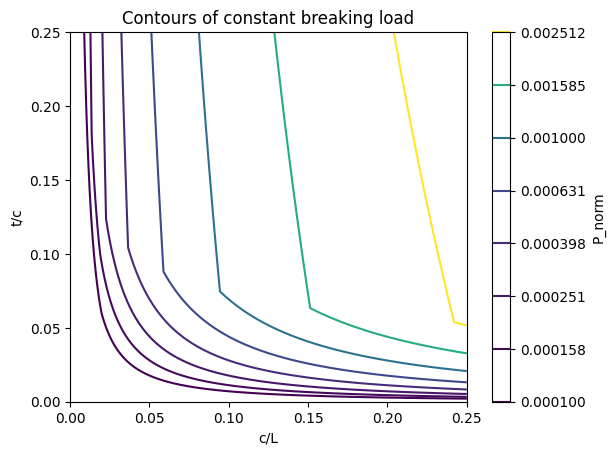

In [51]:
force_spacing = np.logspace(-4,-2.6,8)
plt.figure()
plt.contour(X,Y,force_map,force_spacing)
plt.colorbar(label="P_norm")
plt.xlabel('c/L')
plt.ylabel('t/c')
plt.title('Contours of constant breaking load')

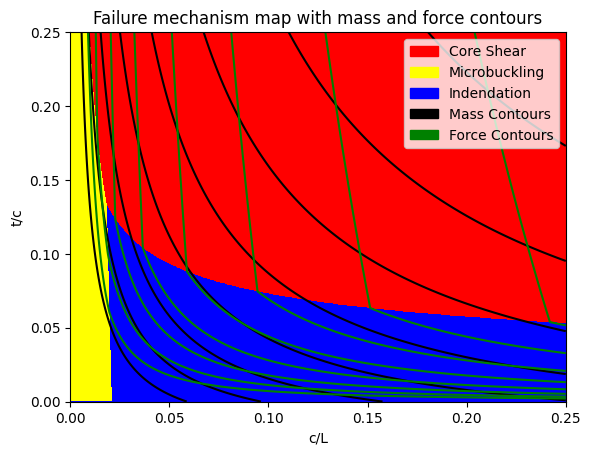

In [52]:
plt.figure()
plot = plt.pcolormesh(X,Y,fail_map)

legend_handles = [
    mpatches.Patch(color=COLOR_1, label='Core Shear'),
    mpatches.Patch(color=COLOR_2, label='Microbuckling'),
    mpatches.Patch(color=COLOR_3, label='Indendation'),
    mpatches.Patch(color='black', label='Mass Contours'),
    mpatches.Patch(color='green', label='Force Contours'),
]

plt.legend(handles=legend_handles)
plt.xlabel('c/L')
plt.ylabel('t/c')
plt.title('Failure mechanism map with mass and force contours')

plt.contour(X,Y,mass_map,mass_spacing,colors=['black'])
plt.contour(X,Y,force_map,force_spacing,colors=['green'])


In [53]:
Mdx, Mdy = np.gradient(mass_map)
slope_direction_mass = np.arctan2(-Mdy,Mdx)
# plt.pcolormesh(X,Y,slope_direction_mass)
# plt.colorbar()


In [54]:
Fdx, Fdy = np.gradient(force_map)
slope_direction_force = np.arctan2(-Fdy,Fdx)
# plt.pcolormesh(X,Y,slope_direction_force)
# plt.colorbar()

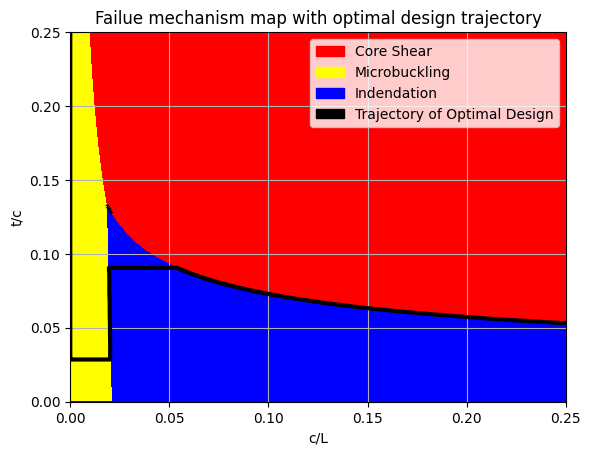

In [ ]:
plt.figure()
plot = plt.pcolormesh(X,Y,fail_map)

legend_handles = [
    mpatches.Patch(color=COLOR_1, label='Core Shear'),
    mpatches.Patch(color=COLOR_2, label='Microbuckling'),
    mpatches.Patch(color=COLOR_3, label='Indendation'),
    mpatches.Patch(color='black', label='Trajectory of Optimal Design'),
]

plt.legend(handles=legend_handles)
plt.xlabel('c/L')
plt.ylabel('t/c')
plt.title('Failue mechanism map with optimal design trajectory')

plt.contour(X,Y,slope_direction_mass-slope_direction_force,0,colors=['black'],linewidths=[3])

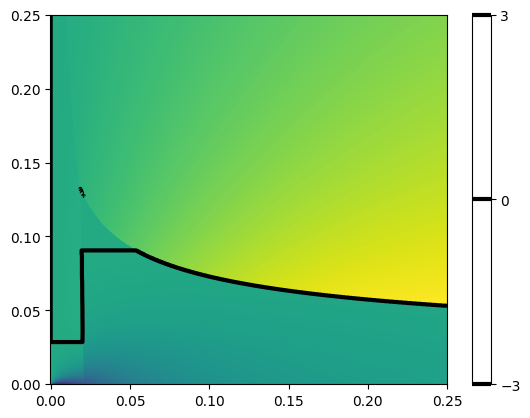

In [56]:
plt.pcolormesh(X,Y,slope_direction_mass-slope_direction_force)
plt.contour(X,Y,slope_direction_mass-slope_direction_force,0,colors=['black'],linewidths=[3])
plt.colorbar()

In [57]:
check = (slope_direction_mass-slope_direction_force).reshape(-1)

force_array = []
mass_array = []
shaped_force = force_map.reshape(-1)
shaped_mass = mass_map.reshape(-1)
for i in range(len(shaped_force)):
    if np.isclose(check[i],0,atol=1e-3):
        force_array.append(shaped_force[i])
        mass_array.append(shaped_mass[i])



[0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 7.82814847e-08
 3.13125939e-07 7.04533362e-07]


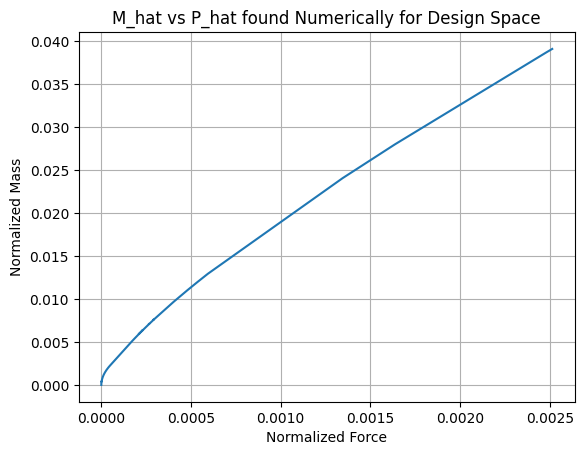

In [58]:
sorted_indices = np.argsort(mass_array)

print(np.asarray(force_array))

mass_sorted = np.asarray(mass_array)[sorted_indices]
force_sorted = np.asarray(force_array)[sorted_indices]

plt.plot(force_sorted,mass_sorted)
plt.xlabel('Normalized Force')
plt.ylabel('Normalized Mass')
plt.title('M_hat vs P_hat found Numerically for Design Space')
plt.grid()

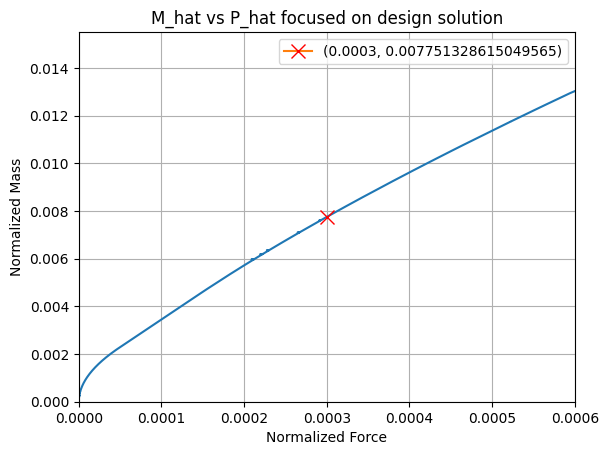

In [59]:
P_hat_true = 75000/(0.2*2.5*face_comp_strength*1000000)
M_hat_true = np.interp(P_hat_true,force_sorted,mass_sorted)

plt.plot(force_sorted,mass_sorted)
plt.xlim([0,P_hat_true*2])
plt.ylim([0,M_hat_true*2])
plt.plot(P_hat_true,M_hat_true,marker='x',markeredgecolor='red',label=f'({P_hat_true}, {M_hat_true})',markersize=10)
plt.legend()
plt.xlabel('Normalized Force')
plt.ylabel('Normalized Mass')
plt.title('M_hat vs P_hat focused on design solution')
plt.grid()

M_hat final is 0.007751328615049565


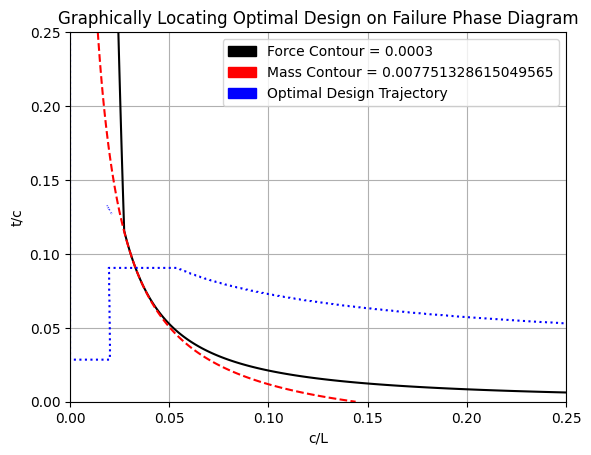

In [60]:
plt.contour(X,Y,force_map-P_hat_true,0,colors=['black'])
plt.contour(X,Y,mass_map-M_hat_true,0,colors=['red'],linestyles='dashed')
plt.contour(X,Y,slope_direction_mass-slope_direction_force,0,colors=['blue'],linestyles='dotted')

new_legend_handles = [
    mpatches.Patch(color='black', label=f'Force Contour = {P_hat_true}'),
    mpatches.Patch(color='red', label=f'Mass Contour = {M_hat_true}'),
    mpatches.Patch(color='blue', label='Optimal Design Trajectory'),
]

plt.legend(handles=new_legend_handles)
plt.grid()
plt.title('Graphically Locating Optimal Design on Failure Phase Diagram')
plt.xlabel('c/L')
plt.ylabel('t/c')

print(f'M_hat final is {M_hat_true}')

In [ ]:
y_final = (3*core_density)/((2*face_density)-(4*core_density))
x_final = M_hat_true / ((2*y_final)+(core_density/face_density))
core_final = x_final*L
thick_final = core_final*y_final

print(f'The final dimensions of the beam are L={L}m, b={b}m, c={core_final*1000}mm, and t={thick_final*1000}mm')

# Checking the results
final_beam = beam(b,core_final,thick_final,face_comp_strength,core_comp_strength,core_shear_strength,face_modulus,L)
print(f'Shear failure force: {fail_shear(final_beam)}')
print(f'Shear failure force: {fail_microbuckle(final_beam)}')
print(f'Shear failure force: {fail_indent(final_beam)}')

The final dimensions of the beam are L=2.5m, b=0.2m, c=82.50284833070825mm, and t=7.46793023683135mm
Shear failure force: 0.08862475374088355
Shear failure force: 0.10750327963132589
Shear failure force: 0.07500039953781484


In [62]:
plt.show()